**Part A: Expert Bayesian Network**

Cell 1: Import required libraries

Outline: Import libraries for probability calculations, data handling, and plotting. Set a fixed random seed so the generated data is reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 42


Cell 2: Define the variables and network structure

Outline: Define all six variables, their possible values, and the directed edges representing the dependencies in the expert Bayesian Network.

In [2]:
states = {
    "Weather": ["Hot", "Mild", "Cold"],
    "DayType": ["Weekday", "Weekend"],
    "Occupancy": ["High", "Low"],
    "AC": ["On", "Off"],
    "ApplianceLoad": ["Heavy", "Light"],
    "EnergyConsumption": ["High", "Low"]
}

parents = {
    "Weather": [],
    "DayType": [],
    "Occupancy": ["DayType"],
    "AC": ["Weather", "Occupancy"],
    "ApplianceLoad": ["Occupancy"],
    "EnergyConsumption": ["AC", "ApplianceLoad"]
}

edges = [
    ("DayType", "Occupancy"),
    ("Weather", "AC"),
    ("Occupancy", "AC"),
    ("Occupancy", "ApplianceLoad"),
    ("AC", "EnergyConsumption"),
    ("ApplianceLoad", "EnergyConsumption")
]

print("Variables:", list(states.keys()))
print("Network edges:")
for edge in edges:
    print(edge[0], "->", edge[1])

Variables: ['Weather', 'DayType', 'Occupancy', 'AC', 'ApplianceLoad', 'EnergyConsumption']
Network edges:
DayType -> Occupancy
Weather -> AC
Occupancy -> AC
Occupancy -> ApplianceLoad
AC -> EnergyConsumption
ApplianceLoad -> EnergyConsumption


Cell 3: Define all expert CPTs

Outline: Store the prior probabilities and conditional probabilities supplied in the question. Each binary variable's complementary probability is calculated as \(1-p\).

In [3]:
cpt = {
    "Weather": {
        (): {"Hot": 0.50, "Mild": 0.30, "Cold": 0.20}
    },
    "DayType": {
        (): {"Weekday": 0.70, "Weekend": 0.30}
    },
    "Occupancy": {
        ("Weekday",): {"High": 0.45, "Low": 0.55},
        ("Weekend",): {"High": 0.80, "Low": 0.20}
    },
    "AC": {
        ("Hot", "High"): {"On": 0.90, "Off": 0.10},
        ("Hot", "Low"): {"On": 0.60, "Off": 0.40},
        ("Mild", "High"): {"On": 0.40, "Off": 0.60},
        ("Mild", "Low"): {"On": 0.15, "Off": 0.85},
        ("Cold", "High"): {"On": 0.10, "Off": 0.90},
        ("Cold", "Low"): {"On": 0.05, "Off": 0.95}
    },
    "ApplianceLoad": {
        ("High",): {"Heavy": 0.75, "Light": 0.25},
        ("Low",): {"Heavy": 0.35, "Light": 0.65}
    },
    "EnergyConsumption": {
        ("On", "Heavy"): {"High": 0.92, "Low": 0.08},
        ("On", "Light"): {"High": 0.68, "Low": 0.32},
        ("Off", "Heavy"): {"High": 0.55, "Low": 0.45},
        ("Off", "Light"): {"High": 0.12, "Low": 0.88}
    }
}

print("Expert CPTs defined successfully.")

Expert CPTs defined successfully.


Cell 4: Verify that every CPT sums to 1

Outline: Check every parent configuration to ensure its conditional probabilities sum to 1. This verifies that the network is a valid probability model.

In [4]:
for variable, table in cpt.items():
    for configuration, probabilities in table.items():
        total = sum(probabilities.values())
        assert np.isclose(total, 1.0), (
            f"Invalid CPT: {variable}, {configuration}, sum={total}"
        )

print("All CPT distributions sum to 1.")

All CPT distributions sum to 1.


Cell 5: Visualize the Bayesian Network

Outline: Draw the six nodes and their directed dependencies. The graph shows how weather and occupancy affect AC usage, while AC usage and appliance load determine energy consumption.

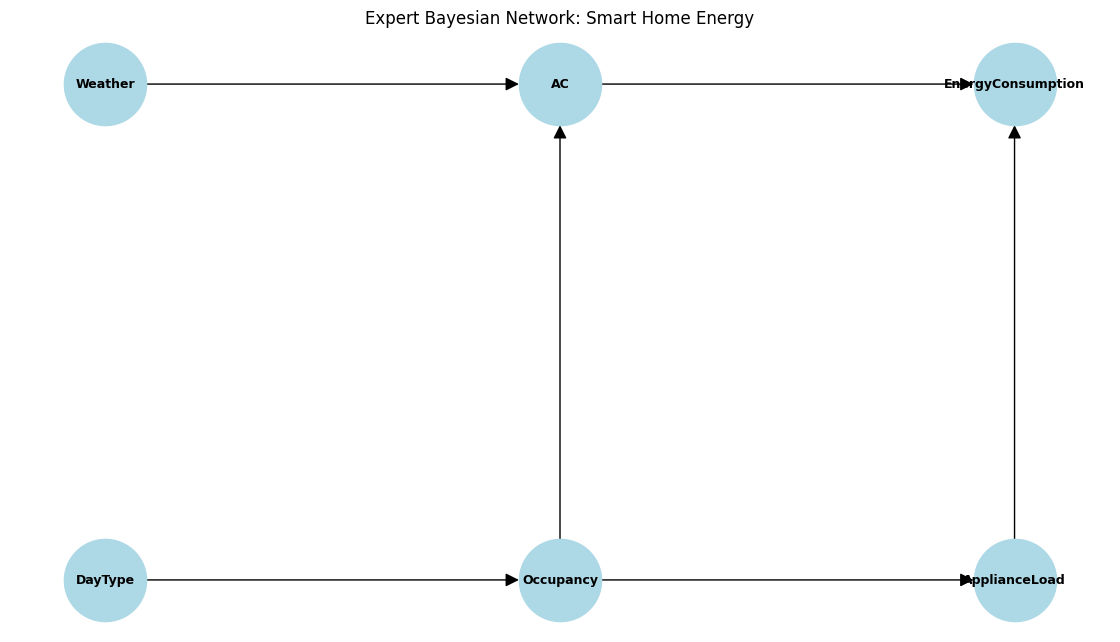

In [5]:
import networkx as nx

G = nx.DiGraph()
G.add_edges_from(edges)

pos = {
    "Weather": (0, 2),
    "DayType": (0, 0),
    "Occupancy": (2, 0),
    "AC": (2, 2),
    "ApplianceLoad": (4, 0),
    "EnergyConsumption": (4, 2)
}

plt.figure(figsize=(11, 6))
nx.draw(
    G, pos, with_labels=True, node_size=3500,
    node_color="lightblue", font_size=9,
    font_weight="bold", arrowsize=20
)
plt.title("Expert Bayesian Network: Smart Home Energy")
plt.show()

Cell 6: Implement probability inference

Outline: Create a general inference function using enumeration. It calculates probabilities by considering every possible assignment of the six variables and summing the joint probabilities consistent with the requested evidence.

In [6]:
topological_order = [
    "Weather", "DayType", "Occupancy",
    "AC", "ApplianceLoad", "EnergyConsumption"
]

def joint_probability(assignment, model):
    probability = 1.0

    for variable in topological_order:
        parent_values = tuple(
            assignment[p] for p in parents[variable]
        )
        probability *= model[variable][parent_values][
            assignment[variable]
        ]

    return probability


def infer(query, evidence, model):
    numerator = 0.0
    denominator = 0.0

    for values in product(*(states[v] for v in topological_order)):
        assignment = dict(zip(topological_order, values))

        if any(assignment[k] != v for k, v in evidence.items()):
            continue

        p = joint_probability(assignment, model)
        denominator += p

        if all(assignment[k] == v for k, v in query.items()):
            numerator += p

    return numerator / denominator if denominator > 0 else np.nan


print("Inference function defined.")

Inference function defined.


Cell 7: Calculate Q1–Q7 for the expert model

Outline: Evaluate all seven requested predictive and diagnostic probabilities using the inference function.

In [7]:
queries = {
    "Q1": ({"EnergyConsumption": "High"}, {}),
    "Q2": ({"EnergyConsumption": "High"}, {"Weather": "Hot"}),
    "Q3": ({"EnergyConsumption": "High"}, {"DayType": "Weekend"}),
    "Q4": ({"EnergyConsumption": "High"},
           {"Weather": "Cold", "Occupancy": "High"}),
    "Q5": ({"Weather": "Hot"}, {"EnergyConsumption": "High"}),
    "Q6": ({"AC": "On"}, {"EnergyConsumption": "High"}),
    "Q7": ({"AC": "On"},
           {"EnergyConsumption": "High", "ApplianceLoad": "Heavy"})
}

def run_queries(model):
    results = {}
    for name, (query, evidence) in queries.items():
        results[name] = infer(query, evidence, model)
    return results

expert_results = run_queries(cpt)

print("Expert Model Results")
for query_name, probability in expert_results.items():
    print(f"{query_name}: {probability:.6f}")

Expert Model Results
Q1: 0.580631
Q2: 0.706266
Q3: 0.640199
Q4: 0.484250
Q5: 0.608188
Q6: 0.692867
Q7: 0.649899


Cell 8: Calculate Q1 by hand

Outline: Expand \(P(E=\text{High})\) over the AC and appliance-load combinations. First calculate the probability of each AC/load combination, then multiply by its conditional probability of high energy consumption.
\[
\begin{aligned}
P(E=H)={}&P(A=On,L=Heavy)P(E=H\mid On,Heavy)\\
&+P(A=On,L=Light)P(E=H\mid On,Light)\\
&+P(A=Off,L=Heavy)P(E=H\mid Off,Heavy)\\
&+P(A=Off,L=Light)P(E=H\mid Off,Light)
\end{aligned}
\]

### Q1: Calculate \(P(EnergyConsumption = High)\) by Hand

We need to calculate:

\[
P(E=High)
\]

Using the law of total probability and the four possible combinations of AC usage and appliance load,

\[
\begin{aligned}
P(E=High)={}&P(A=On,L=Heavy)P(E=High\mid A=On,L=Heavy)\\
&+P(A=On,L=Light)P(E=High\mid A=On,L=Light)\\
&+P(A=Off,L=Heavy)P(E=High\mid A=Off,L=Heavy)\\
&+P(A=Off,L=Light)P(E=High\mid A=Off,L=Light).
\end{aligned}
\]

**Step 1: Calculate the marginal occupancy probabilities.**

Using the DayType and Occupancy CPTs,

\[
\begin{aligned}
P(O=High)
&=P(O=High\mid D=Weekday)P(D=Weekday)\\
&\quad+P(O=High\mid D=Weekend)P(D=Weekend)\\
&=(0.45)(0.70)+(0.80)(0.30)\\
&=0.555.
\end{aligned}
\]

Therefore,

\[
P(O=Low)=1-0.555=0.445.
\]

**Step 2: Calculate the probability of AC being ON for each occupancy level.**

For high occupancy,

\[
\begin{aligned}
P(A=On\mid O=High)
&=(0.50)(0.90)+(0.30)(0.40)+(0.20)(0.10)\\
&=0.590.
\end{aligned}
\]

For low occupancy,

\[
\begin{aligned}
P(A=On\mid O=Low)
&=(0.50)(0.60)+(0.30)(0.15)+(0.20)(0.05)\\
&=0.355.
\end{aligned}
\]

The corresponding probabilities of AC being OFF are \(0.410\) and \(0.645\), respectively.

**Step 3: Calculate the joint probabilities of AC usage and appliance load.**

Using the occupancy probabilities, the AC CPT and the ApplianceLoad CPT:

\[
\begin{aligned}
P(A=On,L=Heavy)
&=(0.555)(0.75)(0.590)\\
&\quad +(0.445)(0.35)(0.355)\\
&=0.30087875.
\end{aligned}
\]

Similarly,

\[
\begin{aligned}
P(A=On,L=Light)
&=(0.555)(0.25)(0.590)\\
&\quad +(0.445)(0.65)(0.355)\\
&=0.18454625.
\end{aligned}
\]

\[
\begin{aligned}
P(A=Off,L=Heavy)
&=(0.555)(0.75)(0.410)\\
&\quad +(0.445)(0.35)(0.645)\\
&=0.27112125.
\end{aligned}
\]

\[
\begin{aligned}
P(A=Off,L=Light)
&=(0.555)(0.25)(0.410)\\
&\quad +(0.445)(0.65)(0.645)\\
&=0.24345375.
\end{aligned}
\]

**Step 4: Substitute into the total probability equation.**

Using the EnergyConsumption CPT,

\[
\begin{aligned}
P(E=High)
={}&(0.30087875)(0.92)\\
&+(0.18454625)(0.68)\\
&+(0.27112125)(0.55)\\
&+(0.24345375)(0.12)\\
={}&0.27680845+0.12549145\\
&+0.1491166875+0.02921445\\
={}&0.5806310375.
\end{aligned}
\]

Therefore,

\[
\boxed{P(EnergyConsumption=High)\approx 0.580631}
\]

The Python inference result is also \(0.580631\), confirming that the hand calculation agrees with the Bayesian Network inference.


In [8]:
p_ac_on = 0
p_load_heavy = 0
p_ac_load = {}

for w in states["Weather"]:
    for d in states["DayType"]:
        for o in states["Occupancy"]:
            p_wo = (
                cpt["Weather"][()][w]
                * cpt["DayType"][()][d]
                * cpt["Occupancy"][(d,)][o]
            )

            for a in states["AC"]:
                p_a = cpt["AC"][(w, o)][a]

                for l in states["ApplianceLoad"]:
                    p_l = cpt["ApplianceLoad"][(o,)][l]
                    p = p_wo * p_a * p_l

                    p_ac_load[(a, l)] = (
                        p_ac_load.get((a, l), 0) + p
                    )

terms = []
for (a, l), p in p_ac_load.items():
    p_high = cpt["EnergyConsumption"][(a, l)]["High"]
    terms.append(p * p_high)
    print(f"P({a}, {l}) = {p:.6f}, contribution = {p*p_high:.6f}")

q1_hand = sum(terms)
print("Q1 calculated by hand:", round(q1_hand, 6))
print("Q1 calculated by inference:", round(expert_results["Q1"], 6))
assert np.isclose(q1_hand, expert_results["Q1"])

P(On, Heavy) = 0.300879, contribution = 0.276808
P(On, Light) = 0.184546, contribution = 0.125491
P(Off, Heavy) = 0.271121, contribution = 0.149117
P(Off, Light) = 0.243454, contribution = 0.029214
Q1 calculated by hand: 0.580631
Q1 calculated by inference: 0.580631


Cell 9: Compare Q6 and Q7 — explaining away

Outline: Compare the probability that the AC is on when high energy consumption is observed, first without knowing appliance load and then with heavy appliance load known.

In [9]:
q6 = expert_results["Q6"]
q7 = expert_results["Q7"]

print(f"Q6 = P(AC=On | Energy=High) = {q6:.6f}")
print(f"Q7 = P(AC=On | Energy=High, Load=Heavy) = {q7:.6f}")
print(f"Change (Q7 - Q6) = {q7 - q6:.6f}")

Q6 = P(AC=On | Energy=High) = 0.692867
Q7 = P(AC=On | Energy=High, Load=Heavy) = 0.649899
Change (Q7 - Q6) = -0.042967


Interpretation:

High energy consumption can be explained by AC usage or heavy appliance load. Once heavy appliance load is known, it provides an alternative explanation for the high consumption. This can reduce the probability that the AC was on. This phenomenon is called explaining away.

**Part B — Conditional Independence Analysis**

Cell 10: Test conditional independence numerically

Outline: Check the three statements using d-separation and compare probabilities before and after conditioning. Two variables are conditionally independent when the relevant conditional probability does not change with the additional evidence, for all possible values being tested.

In [10]:
tests = [
    ("1. Weather independent of DayType",
     {"Weather": "Hot"}, {},
     {"DayType": "Weekend"}),

    ("2. Weather independent of DayType given Energy=High",
     {"Weather": "Hot"}, {"EnergyConsumption": "High"},
     {"DayType": "Weekend"}),

    ("3. Weather independent of ApplianceLoad given Occupancy=High",
     {"Weather": "Hot"}, {"Occupancy": "High"},
     {"ApplianceLoad": "Heavy"})
]

for name, query, evidence, extra in tests:
    p1 = infer(query, evidence, cpt)
    p2 = infer(query, {**evidence, **extra}, cpt)

    print("\n" + name)
    print(f"Without extra evidence: {p1:.6f}")
    print(f"With extra evidence:    {p2:.6f}")
    print("Equal:", np.isclose(p1, p2))


1. Weather independent of DayType
Without extra evidence: 0.500000
With extra evidence:    0.500000
Equal: True

2. Weather independent of DayType given Energy=High
Without extra evidence: 0.608188
With extra evidence:    0.599751
Equal: False

3. Weather independent of ApplianceLoad given Occupancy=High
Without extra evidence: 0.500000
With extra evidence:    0.500000
Equal: True


Cell 11: Display the d-separation conclusions

Outline: Summarize the graphical reasoning for each statement. Remember that conditioning on a collider, or on its descendant, can open a path that was previously blocked.

In [11]:

independence_summary = pd.DataFrame([
    {
        "Statement": "Weather ⊥ DayType",
        "Holds": True,
        "Reason": (
            "The path Weather → AC ← Occupancy ← DayType "
            "is blocked at the collider AC. The path "
            "Weather → AC → EnergyConsumption ← ApplianceLoad "
            "← Occupancy ← DayType is blocked at the collider "
            "EnergyConsumption. Neither collider is observed."
        )
    },
    {
        "Statement": "Weather ⊥ DayType | EnergyConsumption",
        "Holds": False,
        "Reason": (
            "Conditioning on EnergyConsumption opens the path "
            "Weather → AC → EnergyConsumption ← ApplianceLoad "
            "← Occupancy ← DayType. EnergyConsumption is also "
            "a descendant of the collider AC, so conditioning "
            "on it can activate the path "
            "Weather → AC ← Occupancy ← DayType."
        )
    },
    {
        "Statement": "Weather ⊥ ApplianceLoad | Occupancy",
        "Holds": True,
        "Reason": (
            "The path Weather → AC ← Occupancy → ApplianceLoad "
            "is blocked at collider AC. The path "
            "Weather → AC → EnergyConsumption ← ApplianceLoad "
            "is blocked at collider EnergyConsumption. "
            "Conditioning on Occupancy does not open either collider."
        )
    }
])

display(independence_summary)


,Statement,Holds,Reason
0,Weather ⊥ DayType,True,The path Weather → AC ← Occupancy ← DayType is...
1,Weather ⊥ DayType | EnergyConsumption,False,Conditioning on EnergyConsumption opens the pa...
2,Weather ⊥ ApplianceLoad | Occupancy,True,The path Weather → AC ← Occupancy → ApplianceL...


### Numerical Verification of Conditional Independence

**1. Weather ⊥ DayType**

The statement holds. The numerical results are

\[
P(W=Hot)=0.500000
\]

and

\[
P(W=Hot\mid D=Weekend)=0.500000.
\]

The probability does not change after observing DayType, which is consistent with the independence of these variables.

**2. Weather ⊥ DayType | EnergyConsumption**

The statement does not hold. The numerical results are

\[
P(W=Hot\mid E=High)=0.608188
\]

and

\[
P(W=Hot\mid E=High,D=Weekend)=0.599751.
\]

The probabilities differ because conditioning on EnergyConsumption activates a previously blocked path between Weather and DayType. This is an example of dependence induced by conditioning on a collider or its descendant.

**3. Weather ⊥ ApplianceLoad | Occupancy**

The statement holds. The numerical results are

\[
P(W=Hot\mid O=High)=0.500000
\]

and

\[
P(W=Hot\mid O=High,L=Heavy)=0.500000.
\]

Knowing the appliance load does not change the probability of hot weather once occupancy is known. This agrees with the d-separation analysis of the network.


**Part C — Synthetic Data Generation**

Cell 12: Implement ancestral sampling

Outline: Generate one sample by visiting nodes in topological order. At each node, select a value according to its CPT and the values already sampled for its parents.

In [12]:
def sample_one(model, rng):
    sample = {}

    for variable in topological_order:
        parent_values = tuple(
            sample[p] for p in parents[variable]
        )
        distribution = model[variable][parent_values]

        values = list(distribution.keys())
        probabilities = list(distribution.values())

        sample[variable] = rng.choice(
            values, p=probabilities
        )

    return sample


test_rng = np.random.default_rng(SEED)
print("One synthetic sample:")
print(sample_one(cpt, test_rng))

One synthetic sample:
{'Weather': np.str_('Mild'), 'DayType': np.str_('Weekday'), 'Occupancy': np.str_('Low'), 'AC': np.str_('Off'), 'ApplianceLoad': np.str_('Heavy'), 'EnergyConsumption': np.str_('Low')}


Cell 13: Generate datasets of three sizes

Outline: Generate 500, 5,000, and 20,000 observations. Use a separate, fixed seed for each dataset so the results are reproducible and independent of execution order.

In [13]:
dataset_sizes = [500, 5000, 20000]
datasets = {}

for size in dataset_sizes:
    rng = np.random.default_rng(SEED + size)

    records = [
        sample_one(cpt, rng)
        for _ in range(size)
    ]

    datasets[size] = pd.DataFrame(records)

    print(f"Generated dataset with {size} samples.")

print("\nExample from the 500-sample dataset:")
display(datasets[500].head())

Generated dataset with 500 samples.
Generated dataset with 5000 samples.
Generated dataset with 20000 samples.

Example from the 500-sample dataset:


,Weather,DayType,Occupancy,AC,ApplianceLoad,EnergyConsumption
0,Cold,Weekend,High,On,Heavy,High
1,Mild,Weekend,High,Off,Heavy,Low
2,Hot,Weekday,High,On,Heavy,High
3,Hot,Weekday,Low,On,Light,High
4,Hot,Weekday,Low,On,Light,High


Cell 14: Report empirical Weather frequencies

Outline: Count each Weather category and calculate its empirical frequency for all three datasets. Compare these values with the expert probabilities.

In [14]:
weather_rows = []

for size, data in datasets.items():
    counts = data["Weather"].value_counts()

    for weather in states["Weather"]:
        weather_rows.append({
            "Dataset Size": size,
            "Weather": weather,
            "Count": counts.get(weather, 0),
            "Frequency": counts.get(weather, 0) / size,
            "Expert Probability": cpt["Weather"][()][weather]
        })

weather_summary = pd.DataFrame(weather_rows)
display(weather_summary.round(4))

,Dataset Size,Weather,Count,Frequency,Expert Probability
0,500,Hot,269,0.5380,0.5
1,500,Mild,136,0.2720,0.3
2,500,Cold,95,0.1900,0.2
3,5000,Hot,2535,0.5070,0.5
4,5000,Mild,1490,0.2980,0.3
5,5000,Cold,975,0.1950,0.2
6,20000,Hot,9838,0.4919,0.5
7,20000,Mild,6107,0.3054,0.3
8,20000,Cold,4055,0.2028,0.2


Cell 15: Report Weather–Occupancy combinations

Outline: Count all six combinations of Weather and Occupancy for every dataset. This helps identify rare combinations that may cause inaccurate parameter estimates in small datasets.

In [15]:
combination_rows = []

for size, data in datasets.items():
    counts = pd.crosstab(data["Weather"], data["Occupancy"])

    for weather in states["Weather"]:
        for occupancy in states["Occupancy"]:
            combination_rows.append({
                "Dataset Size": size,
                "Weather": weather,
                "Occupancy": occupancy,
                "Count": int(counts.loc[weather, occupancy])
            })

combination_summary = pd.DataFrame(combination_rows)
display(combination_summary)

,Dataset Size,Weather,Occupancy,Count
0,500,Hot,High,143
1,500,Hot,Low,126
2,500,Mild,High,77
3,500,Mild,Low,59
4,500,Cold,High,55
5,500,Cold,Low,40
6,5000,Hot,High,1400
7,5000,Hot,Low,1135
8,5000,Mild,High,813
9,5000,Mild,Low,677


Cell 16: Plot empirical Weather frequencies

Outline: Visualize how the sampled Weather frequencies compare with the expert prior probabilities as the dataset size increases

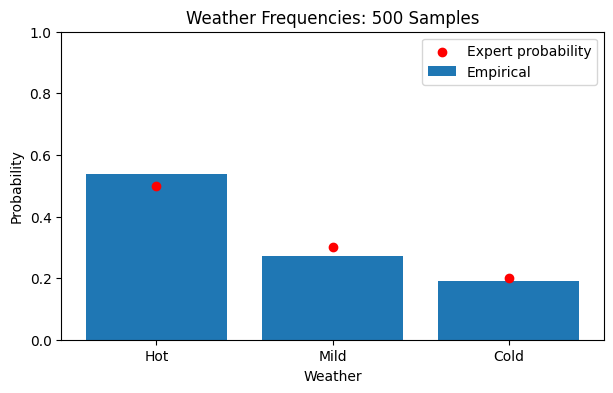

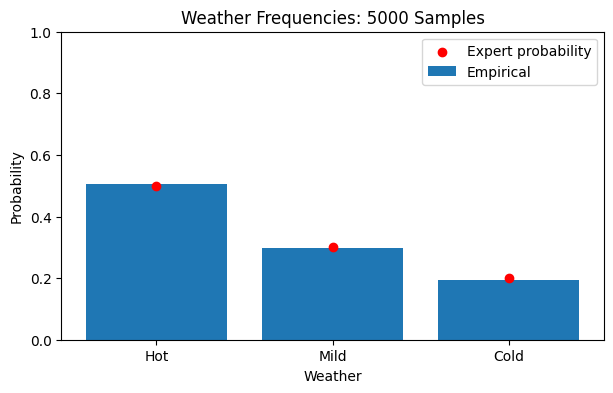

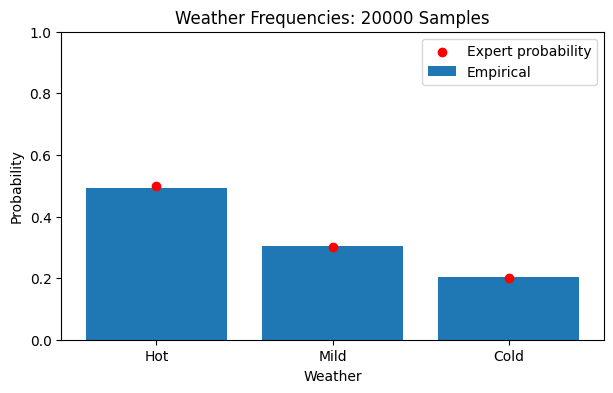

In [16]:
for size in dataset_sizes:
    subset = weather_summary[
        weather_summary["Dataset Size"] == size
    ]

    plt.figure(figsize=(7, 4))
    plt.bar(subset["Weather"], subset["Frequency"], label="Empirical")
    plt.scatter(
        subset["Weather"], subset["Expert Probability"],
        color="red", label="Expert probability", zorder=3
    )

    plt.title(f"Weather Frequencies: {size} Samples")
    plt.xlabel("Weather")
    plt.ylabel("Probability")
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

**Part D — Learning from Data**

Cell 17: Implement MLE and BDeu parameter estimation

Outline: Estimate every CPT from the generated data. MLE uses observed conditional frequencies. BDeu adds a symmetric Dirichlet prior with equivalent sample size 10, which smooths estimates when observations are scarce.

For each variable, let \(q\) be the number of parent configurations and \(r\) the number of possible states. BDeu allocates a prior count of \(10/(qr)\) to each state in each configuration.

In [17]:
def learn_parameters(data, method="MLE", ess=10):
    learned = {}

    for variable in topological_order:
        parent_list = parents[variable]
        parent_configs = list(product(
            *(states[p] for p in parent_list)
        )) if parent_list else [()]

        learned[variable] = {}

        q = len(parent_configs)
        r = len(states[variable])

        for config in parent_configs:
            subset = data

            for parent, value in zip(parent_list, config):
                subset = subset[subset[parent] == value]

            counts = subset[variable].value_counts()
            n = len(subset)

            if method == "MLE":
                if n == 0:
                    probabilities = np.ones(r) / r
                else:
                    probabilities = np.array([
                        counts.get(state, 0) / n
                        for state in states[variable]
                    ])

            elif method == "BDeu":
                alpha = ess / (q * r)
                probabilities = np.array([
                    (counts.get(state, 0) + alpha)
                    / (n + ess / q)
                    for state in states[variable]
                ])

            else:
                raise ValueError("Use 'MLE' or 'BDeu'.")

            learned[variable][config] = dict(
                zip(states[variable], probabilities)
            )

    return learned


learned_models = {}

for size, data in datasets.items():
    learned_models[(size, "MLE")] = learn_parameters(
        data, method="MLE"
    )

    learned_models[(size, "BDeu")] = learn_parameters(
        data, method="BDeu", ess=10
    )

print("MLE and BDeu parameter learning completed.")

MLE and BDeu parameter learning completed.


Cell 18: Verify all learned CPTs

Outline: Confirm that each learned conditional distribution sums to 1 for every parent configuration, for both estimators and all dataset sizes.

In [18]:
for (size, method), model in learned_models.items():
    for variable, table in model.items():
        for config, probabilities in table.items():
            assert np.isclose(sum(probabilities.values()), 1.0), (
                size, method, variable, config
            )

print("All learned CPTs sum to 1.")

All learned CPTs sum to 1.


Cell 19: Display the learned AC CPTs beside the expert CPT

Outline: Compare the probability of AC being on for each Weather–Occupancy configuration. Display the expert, MLE, and BDeu estimates for every dataset size.

In [19]:
ac_rows = []

for config, expert_dist in cpt["AC"].items():
    row = {
        "Weather": config[0],
        "Occupancy": config[1],
        "Expert P(AC=On)": expert_dist["On"]
    }

    for size in dataset_sizes:
        row[f"MLE {size}"] = learned_models[
            (size, "MLE")
        ]["AC"][config]["On"]

        row[f"BDeu {size}"] = learned_models[
            (size, "BDeu")
        ]["AC"][config]["On"]

    ac_rows.append(row)

ac_comparison = pd.DataFrame(ac_rows)
display(ac_comparison.round(4))

,Weather,Occupancy,Expert P(AC=On),MLE 500,BDeu 500,MLE 5000,BDeu 5000,MLE 20000,BDeu 20000
0,Hot,High,0.90,0.9231,0.9182,0.8986,0.8981,0.8931,0.8930
1,Hot,Low,0.60,0.6270,0.6253,0.6264,0.6262,0.5977,0.5977
2,Mild,High,0.40,0.3506,0.3538,0.3850,0.3852,0.3999,0.4000
3,Mild,Low,0.15,0.1525,0.1621,0.1403,0.1412,0.1471,0.1473
4,Cold,High,0.10,0.1091,0.1206,0.1041,0.1053,0.0958,0.0961
5,Cold,Low,0.05,0.0500,0.0680,0.0572,0.0589,0.0489,0.0493


Cell 20: Perform Q1–Q7 for every learned model

Outline: Reuse the same inference function for the learned MLE and BDeu networks. This ensures that all models are evaluated using identical queries.
all_results

In [20]:
all_results = {
    "Expert": expert_results
}

for size in dataset_sizes:
    for method in ["MLE", "BDeu"]:
        model = learned_models[(size, method)]
        all_results[(size, method)] = run_queries(model)

results_rows = []

for size in dataset_sizes:
    for query_name in queries:
        results_rows.append({
            "Dataset Size": size,
            "Query": query_name,
            "Expert": expert_results[query_name],
            "MLE": all_results[(size, "MLE")][query_name],
            "Bayesian": all_results[(size, "BDeu")][query_name]
        })

learned_results_table = pd.DataFrame(results_rows)
display(learned_results_table.round(6))

,Dataset Size,Query,Expert,MLE,Bayesian
0,500,Q1,0.580631,0.576905,0.575538
1,500,Q2,0.706266,0.695716,0.690636
2,500,Q3,0.640199,0.639714,0.633828
3,500,Q4,0.484250,0.474859,0.478517
4,500,Q5,0.608188,0.648799,0.640776
5,500,Q6,0.692867,0.710751,0.706702
6,500,Q7,0.649899,0.676395,0.673443
7,5000,Q1,0.580631,0.593791,0.593613
8,5000,Q2,0.706266,0.725896,0.725285
9,5000,Q3,0.640199,0.654319,0.653683


**Part E — Comparative Analysis**

Cell 21: Create the required comparison tables

Outline: For each dataset size, compare the expert probability with MLE and Bayesian estimates. Calculate the absolute difference between each learned result and the expert result for every query.

In [21]:
comparison_tables = {}

for size in dataset_sizes:
    rows = []

    for query_name in queries:
        expert = expert_results[query_name]
        mle = all_results[(size, "MLE")][query_name]
        bayesian = all_results[(size, "BDeu")][query_name]

        rows.append({
            "Query": query_name,
            "Expert Model": expert,
            "MLE Model": mle,
            "Bayesian Model": bayesian,
            "|Diff| MLE": abs(mle - expert),
            "|Diff| Bayesian": abs(bayesian - expert)
        })

    comparison_tables[size] = pd.DataFrame(rows)

    print(f"\nComparison for dataset size = {size}")
    display(comparison_tables[size].round(6))


Comparison for dataset size = 500


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.580631,0.576905,0.575538,0.003726,0.005093
1,Q2,0.706266,0.695716,0.690636,0.010550,0.015629
2,Q3,0.640199,0.639714,0.633828,0.000485,0.006370
3,Q4,0.484250,0.474859,0.478517,0.009391,0.005733
4,Q5,0.608188,0.648799,0.640776,0.040610,0.032588
5,Q6,0.692867,0.710751,0.706702,0.017884,0.013835
6,Q7,0.649899,0.676395,0.673443,0.026496,0.023544



Comparison for dataset size = 5000


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.580631,0.593791,0.593613,0.013160,0.012981
1,Q2,0.706266,0.725896,0.725285,0.019630,0.019019
2,Q3,0.640199,0.654319,0.653683,0.014121,0.013485
3,Q4,0.484250,0.491568,0.491940,0.007318,0.007690
4,Q5,0.608188,0.619796,0.619037,0.011608,0.010849
5,Q6,0.692867,0.700671,0.700301,0.007805,0.007434
6,Q7,0.649899,0.653398,0.653145,0.003498,0.003246



Comparison for dataset size = 20000


,Query,Expert Model,MLE Model,Bayesian Model,|Diff| MLE,|Diff| Bayesian
0,Q1,0.580631,0.573497,0.573462,0.007134,0.007169
1,Q2,0.706266,0.700775,0.700634,0.005490,0.005632
2,Q3,0.640199,0.631607,0.631463,0.008591,0.008736
3,Q4,0.484250,0.473435,0.473535,0.010815,0.010715
4,Q5,0.608188,0.601069,0.600887,0.007119,0.007301
5,Q6,0.692867,0.687220,0.687131,0.005647,0.005736
6,Q7,0.649899,0.645397,0.645335,0.004503,0.004565


Cell 22: Calculate mean absolute differences

Outline: Compute the mean absolute error (MAE) across Q1–Q7 for MLE and BDeu. A smaller MAE means the learned model's answers are closer to the expert model's answers.
\[
\text{MAE}=\frac{1}{7}\sum_{i=1}^{7}
\left|P_i^{\text{learned}}-P_i^{\text{expert}}\right|
\]

In [22]:
mae_rows = []

for size, table in comparison_tables.items():
    mae_rows.append({
        "Dataset Size": size,
        "MAE MLE": table["|Diff| MLE"].mean(),
        "MAE Bayesian": table["|Diff| Bayesian"].mean()
    })

mae_table = pd.DataFrame(mae_rows)
display(mae_table.round(6))

,Dataset Size,MAE MLE,MAE Bayesian
0,500,0.015592,0.014685
1,5000,0.011020,0.010672
2,20000,0.007043,0.007122


Cell 23: Plot MAE against dataset size

Outline: Plot the mean absolute differences for both estimators. This illustrates how estimation accuracy changes as more synthetic data becomes available.

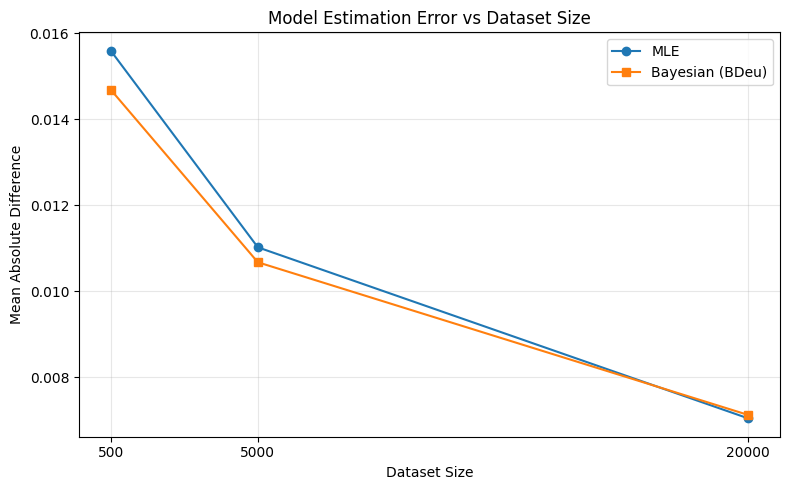

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    mae_table["Dataset Size"],
    mae_table["MAE MLE"],
    marker="o", label="MLE"
)

plt.plot(
    mae_table["Dataset Size"],
    mae_table["MAE Bayesian"],
    marker="s", label="Bayesian (BDeu)"
)

plt.xlabel("Dataset Size")
plt.ylabel("Mean Absolute Difference")
plt.title("Model Estimation Error vs Dataset Size")
plt.xticks(dataset_sizes)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Analysis of the Largest Error for 500 Samples

For the dataset containing 500 samples, Q5, \(P(Weather=Hot\mid EnergyConsumption=High)\), has the largest absolute error for both estimators.

The MLE absolute error is \(0.040610\), whereas the Bayesian estimator's absolute error is \(0.032588\).

The evidence \(EnergyConsumption=High\) occurs in 289 out of 500 samples, corresponding to 57.8% of the dataset. In comparison, the evidence for Q4, \(Weather=Cold\) and \(Occupancy=High\), occurs only 55 times.

Therefore, the largest error cannot be explained simply by saying that Q5 has the rarest evidence. Q5 is a diagnostic query that estimates the probability of a potential cause given an observed effect. Its posterior probability depends on the learned probability distributions for multiple variables and the normalization across possible weather conditions. Estimation errors in these distributions can combine and produce a larger difference from the expert model.

The Bayesian estimator has a smaller error than MLE for Q5 in this experiment, suggesting that the BDeu prior helps reduce estimation error for this query.


Cell 24: Identify the query with the largest error for 500 samples

Outline: Find the query with the largest absolute difference from the expert model for the 500-sample dataset. Then calculate how many samples contain the evidence for that query.

In [24]:
table_500 = comparison_tables[500].copy()

table_500["Maximum Error"] = table_500[
    ["|Diff| MLE", "|Diff| Bayesian"]
].max(axis=1)

largest_query = table_500.loc[
    table_500["Maximum Error"].idxmax()
]

print("Query with the largest error:")
print(largest_query["Query"])
print("MLE absolute error:", largest_query["|Diff| MLE"])
print("Bayesian absolute error:", largest_query["|Diff| Bayesian"])

evidence_counts = []

for query_name, (query, evidence) in queries.items():
    matching = datasets[500]

    for variable, value in evidence.items():
        matching = matching[matching[variable] == value]

    evidence_counts.append({
        "Query": query_name,
        "Evidence": str(evidence) if evidence else "None",
        "Evidence Count": len(matching),
        "Evidence Frequency": len(matching) / 500
    })

evidence_table = pd.DataFrame(evidence_counts)
display(evidence_table)

Query with the largest error:
Q5
MLE absolute error: 0.040610469289346196
Bayesian absolute error: 0.03258801226994368


,Query,Evidence,Evidence Count,Evidence Frequency
0,Q1,None,500,1.000
1,Q2,{'Weather': 'Hot'},269,0.538
2,Q3,{'DayType': 'Weekend'},154,0.308
3,Q4,"{'Weather': 'Cold', 'Occupancy': 'High'}",55,0.110
4,Q5,{'EnergyConsumption': 'High'},289,0.578
5,Q6,{'EnergyConsumption': 'High'},289,0.578
6,Q7,"{'EnergyConsumption': 'High', 'ApplianceLoad':...",210,0.420


Cell 25: Compare errors with evidence frequencies

Outline: Join the error table with evidence counts to examine whether rare evidence is associated with larger errors. Queries with rare evidence have fewer relevant observations and can have less reliable conditional probability estimates.

In [25]:

error_frequency = table_500[
    ["Query", "|Diff| MLE", "|Diff| Bayesian"]
].merge(evidence_table, on="Query")

error_frequency["Maximum Error"] = error_frequency[
    ["|Diff| MLE", "|Diff| Bayesian"]
].max(axis=1)

display(
    error_frequency.sort_values(
        "Maximum Error", ascending=False
    ).round(6)
)


,Query,|Diff| MLE,|Diff| Bayesian,Evidence,Evidence Count,Evidence Frequency,Maximum Error
4,Q5,0.040610,0.032588,{'EnergyConsumption': 'High'},289,0.578,0.040610
6,Q7,0.026496,0.023544,"{'EnergyConsumption': 'High', 'ApplianceLoad':...",210,0.420,0.026496
5,Q6,0.017884,0.013835,{'EnergyConsumption': 'High'},289,0.578,0.017884
1,Q2,0.010550,0.015629,{'Weather': 'Hot'},269,0.538,0.015629
3,Q4,0.009391,0.005733,"{'Weather': 'Cold', 'Occupancy': 'High'}",55,0.110,0.009391
2,Q3,0.000485,0.006370,{'DayType': 'Weekend'},154,0.308,0.006370
0,Q1,0.003726,0.005093,None,500,1.000,0.005093


Cell 26: Print an overall estimator comparison

Outline: Compare the MAE values for both estimators at each dataset size and report which estimator is closer to the expert model for each size.

In [26]:
for _, row in mae_table.iterrows():
    size = int(row["Dataset Size"])
    mle_error = row["MAE MLE"]
    bayesian_error = row["MAE Bayesian"]

    if np.isclose(mle_error, bayesian_error):
        winner = "Both estimators have approximately equal MAE"
    elif mle_error < bayesian_error:
        winner = "MLE has lower MAE"
    else:
        winner = "Bayesian estimation has lower MAE"

    print(
        f"{size} samples: MLE MAE = {mle_error:.6f}, "
        f"Bayesian MAE = {bayesian_error:.6f}. {winner}."
    )

500 samples: MLE MAE = 0.015592, Bayesian MAE = 0.014685. Bayesian estimation has lower MAE.
5000 samples: MLE MAE = 0.011020, Bayesian MAE = 0.010672. Bayesian estimation has lower MAE.
20000 samples: MLE MAE = 0.007043, Bayesian MAE = 0.007122. MLE has lower MAE.


Cell 27: Generate a final summary of results

Outline: Create a concise summary of the MAE results and the best-performing estimator for each dataset size. The output can be used when writing the comparative analysis in your assignment report.

In [27]:
summary_rows = []

for _, row in mae_table.iterrows():
    if row["MAE MLE"] < row["MAE Bayesian"]:
        best = "MLE"
    elif row["MAE Bayesian"] < row["MAE MLE"]:
        best = "Bayesian (BDeu)"
    else:
        best = "Equal"

    summary_rows.append({
        "Dataset Size": int(row["Dataset Size"]),
        "MAE MLE": row["MAE MLE"],
        "MAE Bayesian": row["MAE Bayesian"],
        "Better Estimator": best
    })

final_summary = pd.DataFrame(summary_rows)
display(final_summary.round(6))

,Dataset Size,MAE MLE,MAE Bayesian,Better Estimator
0,500,0.015592,0.014685,Bayesian (BDeu)
1,5000,0.011020,0.010672,Bayesian (BDeu)
2,20000,0.007043,0.007122,MLE


### Comparison of MLE and Bayesian Estimation

For the smaller datasets, Bayesian estimation using the BDeu prior performs slightly better than MLE. With 500 samples, the mean absolute error is 0.014685 for Bayesian estimation compared with 0.015592 for MLE. With 5,000 samples, the corresponding errors are 0.010672 and 0.011020. The BDeu prior uses an equivalent sample size of 10 to smooth parameter estimates, helping reduce variability when some parent configurations have relatively few observations. MLE relies directly on observed conditional frequencies and can be less stable for sparsely observed configurations. However, Bayesian estimation does not outperform MLE in every case: with 20,000 samples, MLE has a slightly lower mean absolute error of 0.007043 compared with 0.007122 for Bayesian estimation. Overall, the errors decrease substantially as the dataset grows, and the advantage of smoothing becomes smaller as more observations become available.


Cell 28: Automatically identify the largest individual error

Outline: Compare the two estimators' errors separately and identify which query has the largest absolute error for each estimator on the 500-sample dataset.

In [28]:
for method, error_column in [
    ("MLE", "|Diff| MLE"),
    ("Bayesian", "|Diff| Bayesian")
]:
    row = comparison_tables[500].loc[
        comparison_tables[500][error_column].idxmax()
    ]

    print(
        f"{method}: largest error is {row['Query']}, "
        f"with absolute difference {row[error_column]:.6f}"
    )

MLE: largest error is Q5, with absolute difference 0.040610
Bayesian: largest error is Q5, with absolute difference 0.032588
